In [1]:

from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta
from scipy.optimize import least_squares
import pandas as pd
import re
import numpy as np
from scipy.interpolate import UnivariateSpline
import matplotlib.pyplot as plt


feriados_cl = pd.read_csv('CLholidays.csv').values.tolist()
feriados_us = pd.read_csv('USholidays.csv').values.tolist()
clpcam = pd.read_csv("mkt_clpcam.csv").values.tolist()
sofr = pd.read_csv("mkt_sofr.csv").values.tolist()

# 1. Cargar el archivo sin encabezados
df_basis = pd.read_csv('curvasBasis.csv', header=None)

# 2. Asignar nombres según el orden que indicaste
# De izquierda a derecha: Tenor, Basis, CLPCamara, SOFR
df_basis.columns = ['Tenor', 'Basis', 'CLPCamara', 'SOFR']

# 3. Limpieza y conversión
# Convertimos a float (por si hay algún string perdido) y dividimos por 100
for col in ['CLPCamara', 'SOFR']:
    df_basis[col] = pd.to_numeric(df_basis[col], errors='coerce') / 100.0

# La base usualmente viene en puntos base (bps), la convertimos a decimal
df_basis['Basis_Dec'] = pd.to_numeric(df_basis['Basis'], errors='coerce') / 10000.0

print("Primeros registros procesados:")
print(df_basis.head())

Primeros registros procesados:
  Tenor  Basis  CLPCamara     SOFR  Basis_Dec
0    1M    0.0    0.04720  0.04081     0.0000
1    2M    0.0    0.04665  0.04052     0.0000
2    3M  -66.0    0.04610  0.04021    -0.0066
3    4M    0.0    0.04580  0.03992     0.0000
4    6M  -60.0    0.04525  0.03934    -0.0060


In [2]:
class legFixed:
    
    def __init__(self, startDate, endDate, schedule, dayCount, discount, fix):
        self.startDate = startDate
        self.endDate = endDate
        self.schedule = schedule
        self.dayCount = dayCount
        self.discount = discount
        self.fix = fix

    def __repr__(self):
        return f"legFixed(startDate={self.startDate}, endDate={self.endDate}, schedule={self.schedule}, dayCount='{self.dayCount}')"

class legFloat:
    
    def __init__(self, startDate, endDate, schedule, dayCount, discount, projection):
        self.startDate = startDate
        self.endDate = endDate
        self.schedule = schedule
        self.dayCount = dayCount
        self.discount = discount
        self.projection = projection

    def __repr__(self):
        return f"legFixed(startDate={self.startDate}, endDate={self.endDate}, schedule={self.schedule}, dayCount='{self.dayCount}')"


class oisSwap:
    
    def __init__(self, tradeDate, calendar, tenor, freq, dayCount, fix, basis=None):
        self.tradeDate = tradeDate
        self.calendar = self.getCalendar(calendar)
        self.tenor = tenor
        self.freq = freq
        self.dayCount = dayCount
        self.discountFixed = []
        self.fix = fix
        self.basis = basis
        self.discountFloat = []
        self.projection = []
        
        self.startDate, self.startDay = self.getStartDate(self.tradeDate, self.calendar)
        self.endDate, self.endDays = self.getEndDate(self.tenor, self.startDate, self.calendar)
        self.schedule, self.scheduleDays, self.scheduleTenorDays, self.tenorDays = self.getSchedule(self.tenor, self.endDate, self.calendar)
        self.fixedLeg = legFixed(self.startDate, self.endDate, self.schedule, self.dayCount, self.discountFixed, self.fix)
        self.floatLeg = legFloat(self.startDate, self.endDate, self.schedule, self.dayCount, self.discountFloat, self.projection)

    def getCalendar(self, calendar):
        calendarMod = []
        for i, row in enumerate(calendar):
            calendarMod.append(datetime.strptime(row[0], '%Y-%m-%d').date())
        return calendarMod
    
    def getStartDate(self, tradeDate, calendar):
        dateMod = tradeDate
        added = 0
        while (added < 2):
            dateMod += timedelta(days=1)
            if (dateMod.weekday() < 5) and (dateMod not in calendar):
                added += 1
        return dateMod, (dateMod - self.tradeDate).days
    
    def getAdjust(self, date, calendar):
            dateMod = date
            while not (dateMod.weekday() < 5) or (dateMod in calendar):
                dateMod += timedelta(days=1)
            if dateMod.month != date.month:
                dateMod = date
                while not (dateMod.weekday() < 5) or (dateMod in calendar):
                    dateMod -= timedelta(days=1)
            return dateMod
        
    def getEndDate(self, tenor, startDate, calendar):
        if 'D' in tenor:
            days = int(tenor.replace('D', ''))
            unadjustedEndDate = startDate + relativedelta(days=days)
        if 'W' in tenor:
            weeks = int(tenor.replace('W', ''))
            unadjustedEndDate = startDate + relativedelta(weeks=weeks)
        elif 'M' in tenor:
            months = int(tenor.replace('M', ''))
            unadjustedEndDate = startDate + relativedelta(months=months)
        elif 'Y' in tenor:
            years = int(tenor.replace('Y', ''))
            unadjustedEndDate = startDate + relativedelta(years=years)
        dateMod = self.getAdjust(unadjustedEndDate, calendar)
        return dateMod, (dateMod - self.tradeDate).days
    
    def gedDaysBetween(self, date1, date2):
        return (date2 - date1).days
        
    def getSchedule(self, tenor, endDate, calendar):
        scheduleMod = []
        scheduleDays = []
        scheduleTenorDays = []
        tenorDays = []
        if self.freq == 'zero':
            scheduleMod.append(self.getAdjust(endDate, calendar))

            # TODO SIEMPRE desde startDate (T+2)
            if tenor == "0D":
                scheduleDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                scheduleTenorDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
            else:
                scheduleDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                scheduleTenorDays.append(self.gedDaysBetween(self.startDate, endDate))
                tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
            


        elif self.freq == 'semiannual':
            cashflows = int(tenor.replace('Y', ''))* 2
            
            for i in range(1, cashflows + 1):
                unadjustedDate = self.startDate + relativedelta(months=6) * i
                adjustedDate = self.getAdjust(unadjustedDate, calendar)
                scheduleMod.append(adjustedDate)
                if i == 1:
                    scheduleDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                else:
                    scheduleDays.append(self.gedDaysBetween(scheduleMod[i-2], scheduleMod[i-1]))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
            tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
        
        elif self.freq == 'anual':
            cashflows = int(tenor.replace('Y', ''))* 1
            
            for i in range(1, cashflows + 1):
                unadjustedDate = self.startDate + relativedelta(months=12) * i
                adjustedDate = self.getAdjust(unadjustedDate, calendar)
                scheduleMod.append(adjustedDate)
                if i == 1:
                    scheduleDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                else:
                    scheduleDays.append(self.gedDaysBetween(scheduleMod[i-2], scheduleMod[i-1]))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
            tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
         
        return scheduleMod, scheduleDays, scheduleTenorDays, tenorDays
    
    def daycount(self):
        """
        Devuelve el factor de daycount para accrual.
        """
        if self.dayCount.lower() == "act/360":
            return 1.0 / 360.0
        elif self.dayCount.lower() == "act/365":
            return 1.0 / 365.0
        else:
            raise ValueError(f"Unsupported day count: {self.dayCount}")



    def __repr__(self):
        return f"oisSwap(tradeDate={self.tradeDate}, tenor={self.tenor}, freq='{self.freq}', dayCount='{self.dayCount}')"

In [3]:


# Supongo que BasisSwap y feriados_cl ya están importados/definidos
tradeDate = datetime.strptime('2025-10-15', '%Y-%m-%d').date()
instcam = {}
instsofr = {}
SCHEDULETENORcam = []
SCHEDULETENORsofr = []

# ---------------------------------------------------------
# 1. Crear el Ancla (0D)
# ---------------------------------------------------------
# Usamos datos de la fila 0, pero forzamos el tenor '0D'
# Ajusta los valores 4.75, 4.12 según tu lógica de mercado actual para el overnight
oisswap_0D_cam = oisSwap(tradeDate, feriados_cl, '0D', 'zero', 'act/360', 
                         4.75/100) # Ojo con el signo del spread

instcam['0D'] = oisswap_0D_cam

# Agregamos el calendario del 0D a la lista general primero
SCHEDULETENORcam.append(oisswap_0D_cam.scheduleTenorDays) 

# ---------------------------------------------------------
# 2. Iterar sobre el DataFrame
# ---------------------------------------------------------
for index, row in df_basis.iterrows():
    tenor_str = row['Tenor']
    clp_val = row['CLPCamara']
    sofr_val = row['SOFR']
    basis_val = row['Basis_Dec']
    
    # Parsear el Tenor
    match = re.match(r"(\d+)([A-Z]+)", tenor_str)
    if match:
        num = int(match.group(1))
        unit = match.group(2)
        
        # Lógica de Frecuencia:
        # Si es Año y >= 2, es semestral (múltiples flujos).
        # Si es Mes (M) o 1Y o 18M, suele ser 'zero' (un solo pago al final).
        if 'Y' in unit and num >= 2:
            frecuencia = 'semiannual'
        else:
            frecuencia = 'zero'
    else:
        frecuencia = 'zero'
        
    # Crear el instrumento
    oisswap_cam = oisSwap(tradeDate, feriados_cl, tenor_str, frecuencia, 'act/360', 
                          clp_val)

    # Guardar en el diccionario
    instcam[oisswap_cam.tenor] = oisswap_cam
    startDate = oisswap_cam.startDate
    
    # CORRECCIÓN AQUÍ: Usar 'basisswap', no 'oisswap'
    SCHEDULETENORcam.append(oisswap_cam.scheduleTenorDays)

print(f"Instrumentos creados: {len(instcam)}")
# Verificamos los primeros y los últimos para ver si la estructura cambió



oisswap_0D_sofr = oisSwap(tradeDate, feriados_us, '0D', 'zero', 'act/360', 
                         4.12/100) # Ojo con el signo del spread

instsofr['0D'] = oisswap_0D_sofr

#Agregamos el calendario del 0D a la lista general primero
SCHEDULETENORsofr.append(oisswap_0D_sofr.scheduleTenorDays) 

# ---------------------------------------------------------
# 2. Iterar sobre el DataFrame
# ---------------------------------------------------------
for index, row in df_basis.iterrows():
    tenor_str = row['Tenor']
    clp_val = row['CLPCamara']
    sofr_val = row['SOFR']
    basis_val = row['Basis_Dec']
    
    # Parsear el Tenor
    match = re.match(r"(\d+)([A-Z]+)", tenor_str)
    if match:
        num = int(match.group(1))
        unit = match.group(2)
        
        # Lógica de Frecuencia:
        # Si es Año y >= 2, es semestral (múltiples flujos).
        # Si es Mes (M) o 1Y o 18M, suele ser 'zero' (un solo pago al final).
        if 'Y' in unit and num >= 2:
            frecuencia = 'anual'
        else:
            frecuencia = 'zero'
    else:
        frecuencia = 'zero'
        
    # Crear el instrumento
    oisswap_sofr = oisSwap(tradeDate, feriados_us, tenor_str, frecuencia, 'act/360', 
                          sofr_val)

    # Guardar en el diccionario
    instsofr[oisswap_sofr.tenor] = oisswap_sofr
    startDate = oisswap_sofr.startDate
    # CORRECCIÓN AQUÍ: Usar 'basisswap', no 'oisswap'
    SCHEDULETENORsofr.append(oisswap_sofr.scheduleTenorDays)

print(f"Instrumentos creados: {len(instsofr)}")




Instrumentos creados: 23


Instrumentos creados: 23


In [4]:
class BasisSwap:
    def __init__(self, tradeDate, calendar, tenor, freq, dayCount, projection1, projection2, basis):
        self.tradeDate = tradeDate
        self.calendar = self.getCalendar(calendar)
        self.tenor = tenor
        self.freq = freq
        self.dayCount = dayCount
        self.projection1 = projection1
        self.projection2 = projection2
        self.basis = basis
        
        self.startDate, self.startDay = self.getStartDate(self.tradeDate, self.calendar)
        self.endDate, self.endDays = self.getEndDate(self.tenor, self.startDate, self.calendar)
        self.schedule, self.scheduleDays, self.scheduleTenorDays, self.tenorDays = self.getSchedule(self.tenor, self.endDate, self.calendar)
        
    def getCalendar(self, calendar):
        calendarMod = []
        for i, row in enumerate(calendar):
            calendarMod.append(datetime.strptime(row[0], '%Y-%m-%d').date())
        return calendarMod
    
    def getStartDate(self, tradeDate, calendar):
        dateMod = tradeDate
        added = 0
        while (added < 2):
            dateMod += timedelta(days=1)
            if (dateMod.weekday() < 5) and (dateMod not in calendar):
                added += 1
        return dateMod, (dateMod - self.tradeDate).days
    
    def getAdjust(self, date, calendar):
            dateMod = date
            while not (dateMod.weekday() < 5) or (dateMod in calendar):
                dateMod += timedelta(days=1)
            if dateMod.month != date.month:
                dateMod = date
                while not (dateMod.weekday() < 5) or (dateMod in calendar):
                    dateMod -= timedelta(days=1)
            return dateMod
        
    def getEndDate(self, tenor, startDate, calendar):
        if 'D' in tenor:
            days = int(tenor.replace('D', ''))
            unadjustedEndDate = startDate + relativedelta(days=days)
        if 'W' in tenor:
            weeks = int(tenor.replace('W', ''))
            unadjustedEndDate = startDate + relativedelta(weeks=weeks)
        elif 'M' in tenor:
            months = int(tenor.replace('M', ''))
            unadjustedEndDate = startDate + relativedelta(months=months)
        elif 'Y' in tenor:
            years = int(tenor.replace('Y', ''))
            unadjustedEndDate = startDate + relativedelta(years=years)
        dateMod = self.getAdjust(unadjustedEndDate, calendar)
        return dateMod, (dateMod - self.tradeDate).days
    
    def gedDaysBetween(self, date1, date2):
        return (date2 - date1).days
        
    def getSchedule(self, tenor, endDate, calendar):
        scheduleMod = []
        scheduleDays = []
        scheduleTenorDays = []
        tenorDays = []
        if self.freq == 'zero':
            scheduleMod.append(self.getAdjust(endDate, calendar))

            # TODO SIEMPRE desde startDate (T+2)
            if tenor == "0D":
                scheduleDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                scheduleTenorDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
            else:
                scheduleDays.append(self.gedDaysBetween(self.tradeDate, endDate))
                scheduleTenorDays.append(self.gedDaysBetween(self.startDate, endDate))
                tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
            


        elif self.freq == 'semiannual':
            cashflows = int(tenor.replace('Y', ''))* 2
            
            for i in range(1, cashflows + 1):
                unadjustedDate = self.startDate + relativedelta(months=6) * i
                adjustedDate = self.getAdjust(unadjustedDate, calendar)
                scheduleMod.append(adjustedDate)
                if i == 1:
                    scheduleDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
                else:
                    scheduleDays.append(self.gedDaysBetween(scheduleMod[i-2], scheduleMod[i-1]))
                    scheduleTenorDays.append(self.gedDaysBetween(self.startDate, adjustedDate))
            tenorDays.append(self.gedDaysBetween(self.startDate, endDate))
         
        return scheduleMod, scheduleDays, scheduleTenorDays, tenorDays
    
    def daycount(self):
        """
        Devuelve el factor de daycount para accrual.
        """
        if self.dayCount.lower() == "act/360":
            return 1.0 / 360.0
        elif self.dayCount.lower() == "act/365":
            return 1.0 / 365.0
        else:
            raise ValueError(f"Unsupported day count: {self.dayCount}")



    def __repr__(self):
        return f"oisSwap(tradeDate={self.tradeDate}, tenor={self.tenor}, freq='{self.freq}', dayCount='{self.dayCount}')"
        

In [5]:


# Supongo que BasisSwap y feriados_cl ya están importados/definidos
tradeDate = datetime.strptime('2025-10-15', '%Y-%m-%d').date()
inst_basis = {}
SCHEDULETENOR = []

# ---------------------------------------------------------
# 1. Crear el Ancla (0D)
# ---------------------------------------------------------
# Usamos datos de la fila 0, pero forzamos el tenor '0D'
# Ajusta los valores 4.75, 4.12 según tu lógica de mercado actual para el overnight
basisswap_0D = BasisSwap(tradeDate, feriados_us, '0D', 'zero', 'act/360', 
                         4.75/100, 4.12/100, (4.12-4.75)/100) # Ojo con el signo del spread

inst_basis['0D'] = basisswap_0D

# ¡IMPORTANTE! Agregamos el calendario del 0D a la lista general primero
SCHEDULETENOR.append(basisswap_0D.scheduleTenorDays) 

# ---------------------------------------------------------
# 2. Iterar sobre el DataFrame
# ---------------------------------------------------------
for index, row in df_basis.iterrows():
    tenor_str = row['Tenor']
    clp_val = row['CLPCamara']
    sofr_val = row['SOFR']
    basis_val = row['Basis_Dec']
    
    # Parsear el Tenor
    match = re.match(r"(\d+)([A-Z]+)", tenor_str)
    if match:
        num = int(match.group(1))
        unit = match.group(2)
        
        # Lógica de Frecuencia:
        # Si es Año y >= 2, es semestral (múltiples flujos).
        # Si es Mes (M) o 1Y o 18M, suele ser 'zero' (un solo pago al final).
        if 'Y' in unit and num >= 2:
            frecuencia = 'semiannual'
        else:
            frecuencia = 'zero'
    else:
        frecuencia = 'zero'
        
    # Crear el instrumento
    basisswap = BasisSwap(tradeDate, feriados_us, tenor_str, frecuencia, 'act/360', 
                          clp_val, sofr_val, basis_val)
    
    # Guardar en el diccionario
    inst_basis[basisswap.tenor] = basisswap
    startDate = basisswap.startDate
    
    # CORRECCIÓN AQUÍ: Usar 'basisswap', no 'oisswap'
    SCHEDULETENOR.append(basisswap.scheduleTenorDays)



print(f"Instrumentos creados: {len(inst_basis)}")


Instrumentos creados: 23


In [6]:
class curve:
    def __init__(self, Inst, discount=None, projection=None, interpolator=None):
        self.Inst = Inst
        self.pillar, self.pillarDays, self.pillarTenorDays, self.tenorDays = self.getPillars()
        
        if Inst == inst_basis:
            self.Basis = self.getBasis()
        else:
            self.market = self.getPar()
        # daycount (factor) lo tomas desde UN swap (todos OIS con misma convención)
        swap0 = next(iter(self.Inst.values()))
        self.dc = swap0.daycount()
        self.discount = discount if discount is not None else []
        self.projection = projection if projection is not None else []
        self.interpolator = self.linearInterpolate if interpolator is None else interpolator 
        self.Fcam = []
        self.Fsofr = []
        self.dfsinter_cam = []
        self.dfsinter_sofr = []
        self.zeros_d = []
    
    def getPillars(self):
        """
        Construye una grilla de pilares CONSISTENTE.

        - pillarTenorDays: días acumulados desde startDate (t) para cada cashflow, únicos y ordenados.
        - pillarDays: delta entre pilares (t_k - t_{k-1}), con t_0 - 0.
        - pillar: fechas asociadas (ordenadas por t).
        - tenorDays: madurez por instrumento (para alinear con market).
        """

        # 1) Recolecta todos los cashflows (t en días desde startDate) + su fecha
        t_to_date = {}  # t(int) -> date
        for key in self.Inst:
            sw = self.Inst[key]
            for t, dt in zip(sw.scheduleTenorDays, sw.schedule):
                t = int(t)
                # si hay duplicados, nos quedamos con la primera fecha (deberían coincidir)
                if t not in t_to_date:
                    t_to_date[t] = dt

        # 2) Ordena por tenor day
        pillarTenorDays = sorted(t_to_date.keys())
        pillarDates = [tradeDate] + [t_to_date[t] for t in pillarTenorDays]

        # 3) pillarDays = deltas entre pilares (en días)
        pillarDays = []
        prev = 0
        for t in pillarTenorDays:
            pillarDays.append(int(t - prev))
            prev = t

        # 4) tenorDays por instrumento (madurez final por instrumento)
        # (para que market y tenorDays queden alineados, ordenar por madurez)
        inst_sorted = sorted(self.Inst.values(), key=lambda sw: int(sw.tenorDays[0]))
        tenorDays = [(startDate - tradeDate).days]+[int(sw.tenorDays[0]) for sw in inst_sorted]
        del tenorDays[1]
        tenorDays = [0] + tenorDays

        pillarTenorDays = tenorDays.copy()

        # guarda en self y retorna
        self.pillar = pillarDates
        self.pillarDays = pillarDays
        self.pillarTenorDays = pillarTenorDays
        self.tenorDays = tenorDays
        

        return self.pillar, self.pillarDays, self.pillarTenorDays, self.tenorDays

    
    def getPar(self):
        inst_sorted = sorted(self.Inst.values(), key=lambda sw: int(sw.tenorDays[0]))
        
        self.market = np.asarray([float(sw.fix) for sw in inst_sorted], dtype=float).reshape(-1)
        
        return self.market
    
    def getBasis(self):
        inst_sorted = sorted(self.Inst.values(), key=lambda sw: int(sw.tenorDays[0]))
        
        self.Basis = np.asarray([float(sw.basis) for sw in inst_sorted], dtype=float).reshape(-1)
        
        return self.Basis



    
    def linearIntepolator(self, x0, x1, y0, y1, x):
        y = y0 + (y1 - y0) * (x - x0) / (x1 - x0)
        return y
    
    def linearInterpolate(self, tenorDays, pillarTenorDays):
        if len(self.discount) != len(tenorDays):
            raise ValueError("discount and tenorDays must match")

        xs = np.asarray(tenorDays, float) / self.dc
        dfs = np.asarray(self.discount, float)
        if np.any(dfs <= 0):
            raise ValueError("DF must be > 0")

        # zero continuo en %: z = -ln(DF)/t
        z = np.zeros_like(xs)
        z[0] = -np.log(dfs[0]) / max(xs[0], 1e-12)
        for i in range(1, len(xs)):
            z[i] = -np.log(dfs[i]) / xs[i]

        # interpolar z lineal en tiempo
        out = []
        for d in pillarTenorDays:
            t = float(d) / self.dc
            if t <= xs[0]:
                zt = z[0]
            elif t >= xs[-1]:
                zt = z[-1]
            else:
                zt = float(np.interp(t, xs, z))
            out.append(float(np.exp(-zt * t)))
        return out
    def loglinearInterpolateDF(self, tenorDays, pillarTenorDays):
        """
        Interpolación log-lineal en DF:
        lineal en log(DF) ⇔ lineal en zero rates continuos.
        """

        if len(self.discount) != len(tenorDays):
            raise ValueError(
                f"Discount curve not initialized: "
                f"len(discount)={len(self.discount)} != len(tenorDays)={len(tenorDays)}"
            )

        xs = np.asarray(tenorDays, dtype=float)
        dfs = np.asarray(self.discount, dtype=float)

        if np.any(dfs <= 0):
            raise ValueError("All discount factors must be > 0.")

        log_dfs = np.log(dfs)

        out = []
        for d in pillarTenorDays:
            d = float(d)

            if d <= xs[0]:
                out.append(float(dfs[0]))
            elif d >= xs[-1]:
                out.append(float(dfs[-1]))
            else:
                out.append(float(np.exp(np.interp(d, xs, log_dfs))))

        return out


    def getForward(self):
        if not self.discount:
            raise ValueError("self.discount is empty. Bootstrap DF first.")

        df_p = self.loglinearInterpolateDF(self.tenorDays, self.pillarTenorDays)

        self.projection = [np.nan]
        for k in range(1, len(self.pillarTenorDays)):
            d0 = float(self.pillarTenorDays[k-1])
            d1 = float(self.pillarTenorDays[k])
            # usamos la convención del OIS (todos usan la misma)
            swap0 = next(iter(self.inst.values()))
            dc = swap0.daycount()
            tau = (d1 - d0) * dc

            fwd = -np.log(df_p[k] / df_p[k-1]) / tau
            self.projection.append(float(fwd))

        return self.projection


    def getProjection(self):
        f = self.projection.copy()
        f = np.asarray(f, dtype=float).reshape(-1)
        proj = f
        return proj
    def CashFlows(self):
        cfs = (self.market - self.getProjection())*self.linearInterpolate(self.discount,self.tenorDays,self.pillarTenorDays)*self.pillarDays*self.dayCount
        PV = np.sum(cfs)
        return PV
    #interes continuo act/360
    #interp lineal

Sofr = curve(instsofr)
cam = curve(instcam)
b4sis = curve(inst_basis)

In [7]:
class iterativeCalibrator:
    def __init__(self, curve):
        self.curve = curve

        # Copias "inmutables" locales (no dependas de que curve se mutee después)
        self.market = curve.market.copy()
        self.tenorDays = curve.tenorDays.copy()                
        self.pillarTenorDays = curve.pillarTenorDays.copy()     
        self.pillarDays = curve.pillarDays.copy()
        self.dc = curve.dc

        # 1) Interpola market (22) a la malla de pilares (65)
        self.pillarMarket = self.linearInterpolate(self.tenorDays, self.pillarTenorDays, self.market)

        # 2) Construye DF por pilar (día -> DF) SIN deduplicar por valor
        self.df_by_day = {}
        for d, r in zip(self.pillarTenorDays, self.pillarMarket):
            # tu fórmula actual (ojo: asume "zero cc", pero lo mantenemos)
            df = np.exp(-(r/100.0) * d * (1/360.0))
            self.df_by_day[d] = float(df)

        # 3) Publica curva de descuento en la MISMA malla que pillarTenorDays
        self.curve.tenorDays = self.pillarTenorDays
        self.curve.discount  = [self.df_by_day[d] for d in self.pillarTenorDays]

    def linearIntepolator(self, x0, x1, y0, y1, x):
        return y0 + (y1 - y0) * (x - x0) / (x1 - x0)

    def linearInterpolate(self, tenorDays, pillarTenorDays, market):
        # tenorDays y market: 22
        # pillarTenorDays: 65
        rate = []
        for day in pillarTenorDays:
            if day in tenorDays:
                j = tenorDays.index(day)
                rate.append(float(market[j-1]))
                continue

            for j in range(1, len(tenorDays)):
                if pillarTenorDays[j] > day:
                    x0, x1 = pillarTenorDays[j-1], pillarTenorDays[j]
                    y0, y1 = float(market[j-1]), float(market[j])
                    rate.append(self.linearIntepolator(x0, x1, y0, y1, day))
                    break
            else:
                rate.append(float(market[-1]))
        return rate

calibrator = iterativeCalibrator(cam)




In [8]:

class solver:
    def __init__(self, Curve, basisclause, calibrator=None):
        self.basisclause = basisclause
        self.Curve = Curve
        self.calibrator = calibrator
        self.dc = Curve.dc
        
        # instrumentos ordenados por madurez
        self.inst_sorted = sorted(Curve.Inst.values(), key=lambda sw: int(sw.scheduleTenorDays[-1]))
        total_inst = len(self.inst_sorted)
        if basisclause:
            self.cut = [6] + list(range(8, total_inst + 1))
            self.indx = 6
        else:
            self.cut = range(total_inst + 1)
            self.indx = 0
        self.inst_cut = list(np.asarray(self.cut) - np.full(len(self.cut), 1))
        
        self.inst_mkt = [self.inst_sorted[i] for i in self.inst_cut]
    
        self.pillarTenorDays = Curve.pillarTenorDays
        self.tenorDays_mkt = self.pillarTenorDays
    
        
        if basisclause:
            self.basis = np.asarray([float(sw.basis) for sw in self.inst_sorted], dtype=float)
            clp_local_rates = np.asarray([float(sw.projection1) for sw in self.inst_sorted], dtype=float)
            
            self.initial_guess = clp_local_rates + self.basis
            self.initial_guess = np.concatenate([[self.initial_guess[0]],self.initial_guess])
            self.initial_guess = self.initial_guess[self.inst_cut]
            
        else:
            self.market = Curve.market
            self.initial_guess = np.concatenate([[self.market[0]],self.market])
            self.initial_guess = np.tile(self.initial_guess,2)

        
        

       

    def objective_function(self, zeros):

        zeros = np.asarray(zeros, dtype=float)  

        Error = []
        error = 0.0
        indx = self.indx
        
        for sw in self.inst_mkt:
            
            
            times = np.asarray(sw.scheduleTenorDays, dtype=float)
            
            
            
            # log-linear DF helper: DF(t) para cualquier t en días
            
            T = list(range(self.pillarTenorDays[-1]+1)) 
            T = np.asarray(T,dtype=float)
            if self.basisclause:
                tenorDaysfil = []
                for k in self.cut:
                    tenorDaysfil.append(self.pillarTenorDays[k])
            else:
                tenorDaysfil = self.pillarTenorDays
        
            
            t_mkt_years = np.asarray(tenorDaysfil,dtype=float) * self.dc 
            def df_at(times_days,df):
                return np.exp(UnivariateSpline(tenorDaysfil,df,k=3,s=0)(times_days))
                
            # accruals por periodo (años)
            accruals = []
            for i,item in enumerate(sw.scheduleTenorDays):
                if len(sw.scheduleTenorDays) == 1:
                    accruals.append((sw.scheduleTenorDays[i])*self.dc)
                else:
                    accruals.append((sw.scheduleTenorDays[i] - sw.scheduleTenorDays[i-1])*self.dc)
                    accruals[0] = (sw.scheduleTenorDays[0])*self.dc
            accruals = np.asarray(accruals,dtype=float)
            accruals2 = np.diff(np.concatenate([[4.0], times])) * self.dc
            accruals3 = np.diff(np.concatenate([[-1.0], T])) * self.dc
            
            

            # Fcam = np.asarray(flotcam[indx])
            # Fsofr = np.asarray(flotsofr[indx]) (Por si se desea usar los índices forward)
            
            


            
            if self.basisclause:
                b = float(sw.basis) # Basis spread por si se quiere usar
                DF_mkt = np.exp(-(zeros) * t_mkt_years)
                zeros_d_cortados = np.asarray([b4sis.zeros_d[k] for k in self.inst_cut])
                DF_mkt2 = np.exp(-(zeros_d_cortados) * t_mkt_years)
                logDF = np.log(DF_mkt)
                logDF2 = np.log(DF_mkt2)
                dfs = np.array(df_at(times,logDF))
                if indx == 0: dfs[0] = 1.0
                
                dfs2 = np.array(df_at(times, logDF2))
                dfsinter_cam = np.asarray(b4sis.dfsinter_cam)
                dfsinter_sofr= np.asarray(b4sis.dfsinter_sofr)
                Flotcam = []
                Flotsofr = []
                for (Ffil,dfsinter) in [(Flotcam,dfsinter_cam),(Flotsofr,dfsinter_sofr)]:
                    if indx == 0:
                        fwd = -(1 - dfsinter[0]/dfsinter[cam.pillarTenorDays[1]])/(cam.pillarTenorDays[1]*self.dc)
                        Ffil.append(fwd)
                    else:
                        for k,day in enumerate(sw.scheduleTenorDays):
                            
                            if k == 0:
                                fwd = -(1 - dfsinter[cam.pillarTenorDays[1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                            elif k >= 1:
                                fwd = -(1 - dfsinter[sw.scheduleTenorDays[k-1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                            Ffil.append(fwd)
                


                if len(sw.scheduleTenorDays) > 1:
                    accruals = accruals[1:]
                    dfs21 = dfs2[:-1]
                    dfs22 = dfs2[1:]
                    Flotsofr = Flotsofr[1:]
                    dfs = dfs[:-1]
                else:
                    dfs21 = dfs2
                    dfs22 = dfs2
                B = Flotsofr - (1/accruals)*(dfs21/dfs22 - 1)

                PV = (accruals*(dfs22/dfs21)*dfs*B) # Aporximación valor presente para tenores largos, sin tipo de cambio FX
                
                
            else:
                zeros_d = zeros[:24] #  Ceros de descuento
                zeros_p = zeros[24:] # Ceros de proyección 
                # DF curva descuento en malla de mercado
                DF_mkt = np.exp(-(zeros_d) * t_mkt_years)
                # DF curva proyección en malla de mercado 
                DF_mkt2 = np.exp(-(zeros_p) * t_mkt_years)
                logDF = np.log(DF_mkt)
                logDF2 = np.log(DF_mkt2)
                dfs = np.array(df_at(times,logDF))
                if indx == 0: dfs[0] = 1.0
                dfsinter = list(df_at(T,logDF2))
                R = float(sw.fix)
                Ffil = []
                F = []
        
                if indx == 0:
                    fwd = -(1 - dfsinter[0]/dfsinter[cam.pillarTenorDays[1]])/(cam.pillarTenorDays[1]*self.dc)
                    Ffil.append(fwd)
                else:
                    for k,day in enumerate(sw.scheduleTenorDays):
                        
                        if k == 0:
                            fwd = -(1 - dfsinter[cam.pillarTenorDays[1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                        elif k >= 1:
                            fwd = -(1 - dfsinter[sw.scheduleTenorDays[k-1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                        Ffil.append(fwd)

                for k in range(1,len(T)):   
                    F.append(-100*(np.log(dfsinter[k])-np.log(dfsinter[k-1])) / accruals3[k])
                     
                    
                Ffil = np.asarray(Ffil,dtype=float)
                PV = (dfs*accruals * (np.full(len(Ffil),R) - (Ffil)))
                
            if self.Curve == Sofr: 
                b4sis.Fsofr = F
                b4sis.zeros_d = zeros_d
                b4sis.dfsinter_sofr = dfsinter
            if self.Curve == cam: 
                b4sis.Fcam = F
                b4sis.dfsinter_cam = dfsinter
            error = np.sum(PV)**2
            Error.append(error)
            indx += 1
            self.dfs = dfs
            
        
            
            
        return np.asarray(Error,dtype=float)

       


    def solve(self):
        bl = 0.95*self.initial_guess
        bh = 1.05*self.initial_guess
        
        bounds = (bl,bh)

        res = least_squares(
            self.objective_function,
            x0=self.initial_guess,
            bounds=bounds,
            ftol=1e-04,
            xtol=8e-04,
            gtol=None,
            max_nfev=200
            
        )

        if not res.success:
            raise RuntimeError(res.message)

        return res.x

   

   


In [9]:
ss_cam = solver(cam, False, calibrator)
x_cam = ss_cam.solve()

print(x_cam)

[0.0475     0.0475     0.0472     0.04665    0.0461     0.0458
 0.04525001 0.04469997 0.04445087 0.04460085 0.04490249 0.04575456
 0.04670564 0.04760689 0.04845801 0.04925885 0.0499604  0.05055784
 0.05116856 0.05207577 0.05295732 0.05351163 0.05377575 0.05382381
 0.0475     0.04983851 0.0472     0.04665    0.0461     0.0458
 0.04525    0.0447     0.04445    0.04459998 0.0449     0.04575
 0.04669999 0.04759999 0.04844999 0.04925    0.04995002 0.05055002
 0.05115006 0.0520501  0.05290025 0.05345039 0.05370042 0.05380028]


In [10]:
ss_sofr = solver(Sofr, False, calibrator)
x_sofr = ss_sofr.solve()

print(x_sofr)

[0.0412     0.0412     0.04081    0.04052    0.04021    0.03992
 0.03934002 0.0385201  0.03785361 0.03672122 0.03610442 0.0357352
 0.03585814 0.03618108 0.03659345 0.03704496 0.03751589 0.03797485
 0.03842599 0.03925676 0.04024808 0.04106761 0.04118059 0.04092834
 0.0412     0.04092243 0.04080725 0.04051526 0.04020095 0.03990461
 0.03929458 0.03834296 0.03740362 0.03585442 0.03545886 0.03506071
 0.03518323 0.03551764 0.03595108 0.03643199 0.036942   0.03744728
 0.03794924 0.03889364 0.0400577  0.04100584 0.04102982 0.04047401]


In [11]:
ss_basis = solver(b4sis, True, calibrator)
x_basis = ss_basis.solve()

In [12]:
def objective_function(self, zeros):

        zeros = np.asarray(zeros, dtype=float)  

        Error = []
        error = 0.0
        
        indx = self.indx
        for sw in self.inst_mkt:
        
            
            times = np.asarray(sw.scheduleTenorDays, dtype=float)
            
            
            # log-linear DF helper: DF(t) para cualquier t en días
            
            T = list(range(self.pillarTenorDays[-1]+1)) 
            T = np.asarray(T,dtype=float)
            tenorDaysfil = []
            for k in self.cut:
                tenorDaysfil.append(self.pillarTenorDays[k])  
                        
            
            t_mkt_years = np.asarray(tenorDaysfil,dtype=float) * self.dc 
            def df_at(times_days,df):
                return np.exp(UnivariateSpline(tenorDaysfil,df,k=1,s=0)(times_days))
                
       
            # accruals por periodo (años)
            accruals = []
            for i,item in enumerate(sw.scheduleTenorDays):
                if len(sw.scheduleTenorDays) == 1:
                    accruals.append((sw.scheduleTenorDays[i])*self.dc)
                else:
                    accruals.append((sw.scheduleTenorDays[i] - sw.scheduleTenorDays[i-1])*self.dc)
                    accruals[0] = (sw.scheduleTenorDays[0])*self.dc
            accruals = np.asarray(accruals,dtype=float)
            accruals2 = np.diff(np.concatenate([[4.0], times])) * self.dc
            accruals3 = np.diff(np.concatenate([[-1.0], T])) * self.dc
            

            
            if self.basisclause:
                b = float(sw.basis)
                DF_mkt = np.exp(-(zeros) * t_mkt_years)
                zeros_d_cortados = np.asarray([b4sis.zeros_d[k] for k in self.inst_cut])
                DF_mkt2 = np.exp(-(zeros_d_cortados) * t_mkt_years)
                logDF2 = np.log(DF_mkt2)
                logDF = np.log(DF_mkt)
                dfs = np.array(df_at(times,logDF))
                if indx == 0: dfs[0] = 1.0
                
                dfs2 = np.array(df_at(times, logDF2))
                dfsinter_cam = np.asarray(b4sis.dfsinter_cam)
                dfsinter_sofr= np.asarray(b4sis.dfsinter_sofr)
                Flotcam = []
                Flotsofr = []
                for (Ffil,dfsinter) in [(Flotcam,dfsinter_cam),(Flotsofr,dfsinter_sofr)]:
                    if indx == 0:
                        fwd = -(1 - dfsinter[0]/dfsinter[cam.pillarTenorDays[1]])/(cam.pillarTenorDays[1]*self.dc)
                        Ffil.append(fwd)
                    else:
                        for k,day in enumerate(sw.scheduleTenorDays):
                            
                            if k == 0:
                                fwd = -(1 - dfsinter[cam.pillarTenorDays[1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                            elif k >= 1:
                                fwd = -(1 - dfsinter[sw.scheduleTenorDays[k-1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                            Ffil.append(fwd)
                

                if len(sw.scheduleTenorDays) > 1:
                    accruals = accruals[1:]
                    dfs21 = dfs2[:-1]
                    dfs22 = dfs2[1:]
                    Flotsofr = Flotsofr[1:]
                    dfs = dfs[:-1]
                else:
                    dfs21 = dfs2
                    dfs22 = dfs2
                    
                B = Flotsofr - (1/accruals)*(dfs21/dfs22 - 1)

                PV = (accruals*(dfs22/dfs21)*dfs*B)
                
                
                
            else:
                zeros_d = zeros[:24]
                zeros_p = zeros[24:]
                # DF curva descuento en malla de mercado 
                DF_mkt = np.exp(-(zeros_d) * t_mkt_years)
                # DF curva proyección en malla de mercado 
                DF_mkt2 = np.exp(-(zeros_p) * t_mkt_years)
                logDF = np.log(DF_mkt)
                logDF2 = np.log(DF_mkt2)
                dfs = np.array(df_at(times,logDF))
                if indx == 0: dfs[0] = 1.0
                dfsinter = list(df_at(T,logDF2))
                R = float(sw.fix)
                Ffil = []
                F = []
        
                if indx == 0:
                    fwd = -(1 - dfsinter[0]/dfsinter[cam.pillarTenorDays[1]])/(cam.pillarTenorDays[1]*self.dc)
                    Ffil.append(fwd)
                else:
                    for k,day in enumerate(sw.scheduleTenorDays):
                        
                        if k == 0:
                            fwd = -(1 - dfsinter[cam.pillarTenorDays[1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                        elif k >= 1:
                            fwd = -(1 - dfsinter[sw.scheduleTenorDays[k-1]]/dfsinter[sw.scheduleTenorDays[k]])/accruals2[k]
                        Ffil.append(fwd)

                for k in range(1,len(T)):   
                    F.append(-100*(np.log(dfsinter[k])-np.log(dfsinter[k-1])) / accruals3[k])
                     
                    
                Ffil = np.asarray(Ffil,dtype=float)
                PV = (dfs*accruals * (np.full(len(Ffil),R) - (Ffil)))
                
                
            if self.Curve == Sofr: 
                b4sis.Fsofr = F
                b4sis.zeros_d = zeros_d
                b4sis.dfsinter_sofr = dfsinter
            if self.Curve == cam: 
                b4sis.Fcam = F
                b4sis.dfsinter_cam = dfsinter
            error = np.sum(PV)**2
            Error.append(error)
            indx += 1
            
            
            
            
objective_function(ss_basis, x_basis)

In [13]:
print(ss_basis.initial_guess)
print(x_basis)

[0.0458  0.0393  0.03865 0.03935 0.0404  0.04195 0.04355 0.0447  0.04545
 0.04605 0.0466  0.04715 0.0475  0.04825 0.04915 0.04925 0.04895]
[0.04809    0.041265   0.0405825  0.03738348 0.04241908 0.04404651
 0.04572651 0.04693397 0.04772147 0.04835143 0.04427112 0.04950641
 0.04987395 0.05066132 0.04672757 0.05170774 0.05139401]


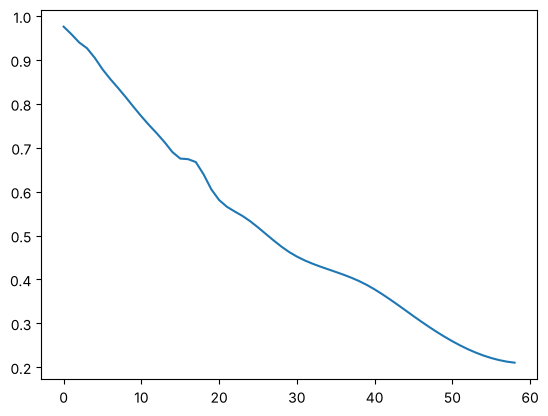

In [14]:
plt.plot(range(59),ss_basis.dfs)



Para graficar las curvas CLPCam/SOFR:

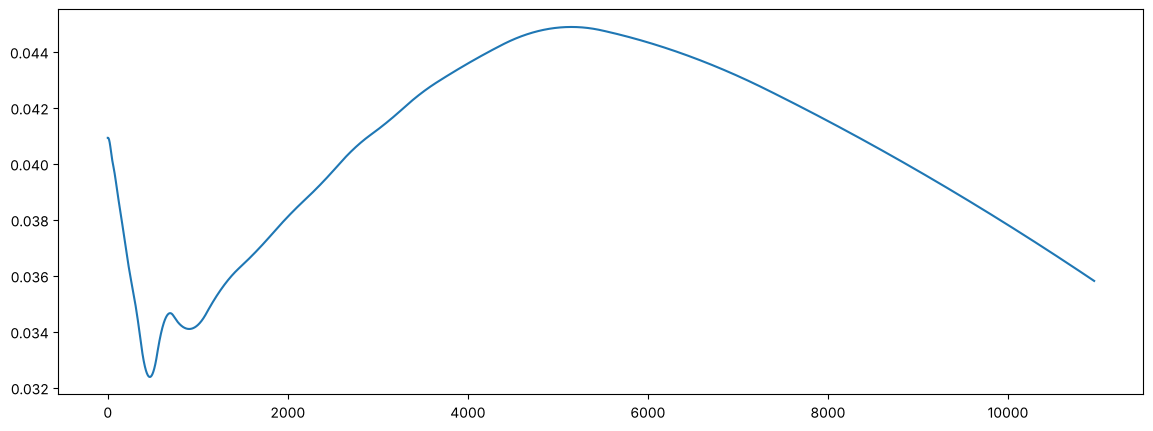

In [15]:

def objective_function2(self, zeros):

        zeros = np.asarray(zeros, dtype=float) 
       
        indx = 0
        Error = []
        error = 0.0
        
        dfsinter2=[]
        savedLenght = 0
        Ffin = []
        plt.figure(figsize=(14,5))
        for sw in self.inst_sorted: 
            
            
            zeros_d = zeros[:24]
            zeros_p = zeros[24:]
            R = float(sw.fix/100)
            times = np.asarray(sw.scheduleTenorDays, dtype=float)
            t_mkt_years = np.asarray(cam.pillarTenorDays,dtype=float) * self.dc # días
            
            # DF curva descuento en malla de mercado
            DF_mkt = np.exp(-(zeros_d / 100.0) * t_mkt_years)
            # DF curva proyección en malla de mercado (
            DF_mkt2 = np.exp(-(zeros_p / 100.0) * t_mkt_years)
            # log-linear DF helper: DF(t) para cualquier t en días
            logDF = np.log(DF_mkt)
            logDF2 = np.log(DF_mkt2)
            T = list(range(cam.pillarTenorDays[-1]+1))                
            T = np.asarray(T,dtype=float)
            def df_at(times_days,df):
                return np.exp(UnivariateSpline(cam.pillarTenorDays,df,k=3,s=0)(times_days))
            
            
            
            dfsinter = list(df_at(T,logDF2))
            
            dfsinter2 += dfsinter[savedLenght:]
            
                
            
            accruals3 = np.diff(np.concatenate([[-1.0], T])) * self.dc
            
            
            F = [] 
            Ffil = []
            if indx == 0:
                for k in range(sw.scheduleTenorDays[0]):
                    fwd = 100*np.log(dfsinter[k]/dfsinter[k+1])/(accruals3[k+1])
                    Ffil.append(fwd)
            else:
                for k in range(sw.scheduleTenorDays[0],sw.scheduleTenorDays[-1]+1):
                    
                    fwd = 100*np.log(dfsinter[k-1]/dfsinter[k])/accruals3[k]
                    Ffil.append(fwd)
                    Ffin.append(fwd)

            
            for k in range(1,len(T)):   
                F.append(-100*(np.log(dfsinter[k])-np.log(dfsinter[k-1])) / accruals3[k])
           
            
            Ffil = np.asarray(Ffil,dtype=float)
            indx += 1     

            
            
        plt.plot(range(len(F)),F)

            
        Ffin = np.asarray(Ffin,dtype=float)
        

        plt.show()
        
       
objective_function2(ss_sofr,x_sofr)
